In [2]:
import sys
from pathlib import Path

# Add project root to sys.path so we can import utils
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

from utils.plotting import PALETTE, plot_cdf, plot_pdf, set_style

# Apply unified design system
set_style()
np.random.seed(42)

# Weibull Distribution: Reliability Engineering & Aging Dynamics

## 1. Intuition & Motivation

The **Exponential distribution** models components that never age: an electronic resistor or radioactive atom has the exact same probability of failing in the next hour regardless of whether it is 1 hour old or 10,000 hours old (the **memoryless property**).

In physical and mechanical systems, this assumption fails:
- **Infant mortality ($k < 1$):** Defective parts fail early during "burn-in"; surviving parts are sturdier.
- **Constant random risk ($k = 1$):** Failures are caused purely by external shock; identical to the Exponential distribution.
- **Wear-out and aging ($k > 1$):** Fatigue, friction, corrosion, and wear-and-tear increase the likelihood of failure as operating hours accumulate.

The **hazard function** $h(t)$ quantifies the instantaneous failure rate given survival up to time $t$:
$$h(t) = \lim_{\Delta t \to 0} \frac{P(t \le X < t + \Delta t \mid X \ge t)}{\Delta t} = \frac{f(t)}{S(t)} = \frac{k}{\lambda} \left(\frac{t}{\lambda}\right)^{k-1}$$

The Weibull distribution models this entire spectrum using just two parameters: shape $k$ and scale $\lambda$.

In [3]:
# Time evaluation grid (avoid t=0 to prevent division by zero when k < 1)
t = np.linspace(0.05, 5.0, 500)
scale_lambda = 2.0

# Shape parameters representing the fundamental aging regimes
shapes = [0.6, 1.0, 2.0, 3.5]
labels = [
    "k = 0.6 (Infant Mortality / Burn-in)",
    "k = 1.0 (Constant Risk / Memoryless)",
    "k = 2.0 (Linear Wear-out / Rayleigh)",
    "k = 3.5 (Accelerated Fatigue / Wear-out)",
]

# Use valid palette tokens from utils/plotting.py alongside an accent tone
colors = [PALETTE["secondary"], PALETTE["primary"], PALETTE["accent"], "#2ca02c"]

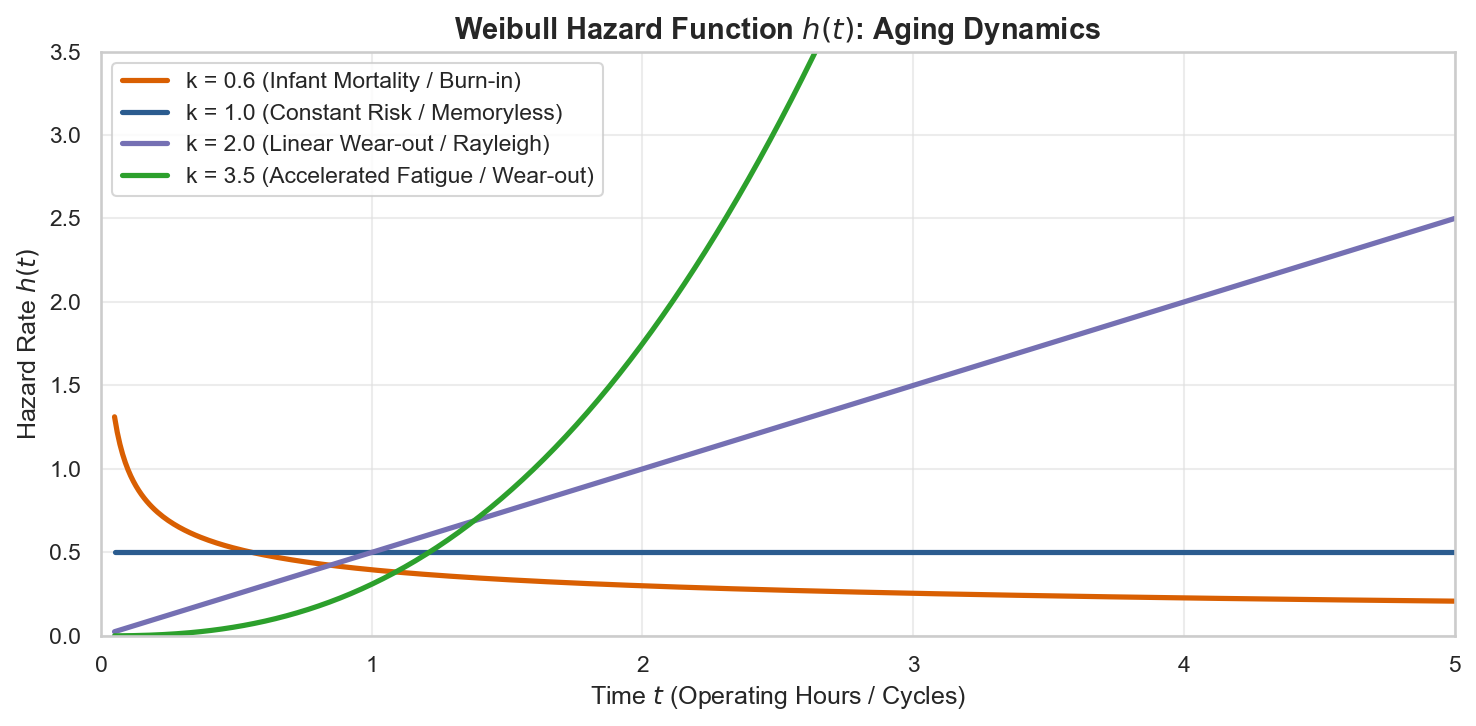

In [4]:
fig, ax = plt.subplots(figsize=(10, 5))

for k, label, color in zip(shapes, labels, colors):
    # Weibull hazard function: h(t) = (k / lambda) * (t / lambda)**(k - 1)
    h_t = (k / scale_lambda) * (t / scale_lambda) ** (k - 1)
    ax.plot(t, h_t, label=label, color=color, linewidth=2.5)

ax.set_title("Weibull Hazard Function $h(t)$: Aging Dynamics", fontsize=14, fontweight="bold")
ax.set_xlabel("Time $t$ (Operating Hours / Cycles)", fontsize=12)
ax.set_ylabel("Hazard Rate $h(t)$", fontsize=12)
ax.set_ylim(0, 3.5)
ax.set_xlim(0, 5.0)
ax.legend(frameon=True, facecolor="white", loc="upper left")

plt.tight_layout()
plt.show()

## 2. Mathematical Definition

A continuous random variable $X$ follows a **Weibull distribution** with shape parameter $k > 0$ and scale parameter $\lambda > 0$ ($X \sim \text{Weibull}(k, \lambda)$) if its probability density function (PDF) is:

$$f(x; k, \lambda) = \frac{k}{\lambda} \left(\frac{x}{\lambda}\right)^{k-1} \exp\left(-\left(\frac{x}{\lambda}\right)^k\right), \quad x \ge 0$$

### Cumulative Distribution Function (CDF) & Survival Function $S(x)$
$$F(x) = P(X \le x) = 1 - \exp\left(-\left(\frac{x}{\lambda}\right)^k\right)$$

The **Survival function** $S(x)$ (reliability at time $x$) is the complement of the CDF:
$$S(x) = P(X > x) = 1 - F(x) = \exp\left(-\left(\frac{x}{\lambda}\right)^k\right)$$

### Hazard Function $h(x)$
$$h(x) = \frac{f(x)}{S(x)} = \frac{k}{\lambda} \left(\frac{x}{\lambda}\right)^{k-1}$$

### Parameters & Support
- **Support:** $x \in [0, \infty)$
- **Shape parameter $k > 0$:** Governs aging physics ($k < 1$ infant mortality, $k = 1$ constant risk, $k > 1$ wear-out).
- **Scale parameter $\lambda > 0$:** Characteristic life. At $x = \lambda$, exactly $1 - e^{-1} \approx 63.2\%$ of units fail regardless of $k$.

> **SciPy Parameter Trap:** In `scipy.stats`, the standard engineering Weibull is `stats.weibull_min(c, scale)` where `c = k` (shape) and `scale = lambda`.

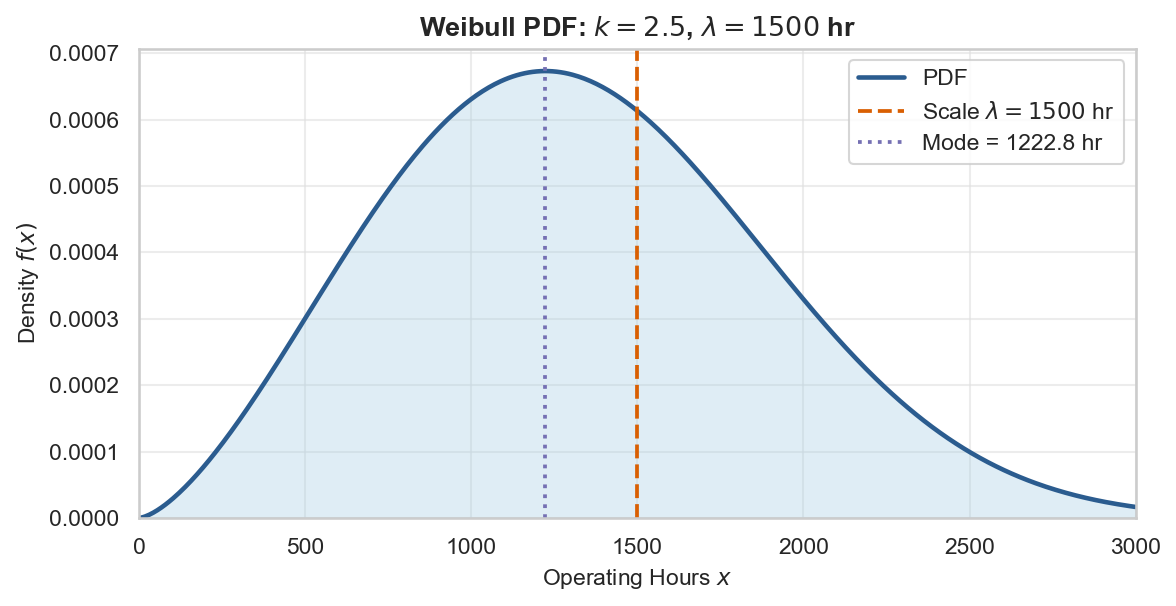

Scale parameter (Characteristic Life lambda): 1500.0 hours
Distribution Mode (Peak failure density time): 1222.8 hours
Peak PDF Density at Mode:                     0.000673


In [7]:
# Parameters: k = 2.5 (wear-out aging), lambda = 1500 hours (characteristic life)
k_shape = 2.5
lambda_scale = 1500.0

x_axis = np.linspace(0.01, 3000, 500)
weibull_dist = stats.weibull_min(c=k_shape, scale=lambda_scale)
pdf_values = weibull_dist.pdf(x_axis)

# Mode formula for k > 1: mode = lambda * ((k - 1) / k)**(1 / k)
weibull_mode = lambda_scale * ((k_shape - 1) / k_shape) ** (1 / k_shape)

fig, ax = plt.subplots(figsize=(8, 4.2))
plot_pdf(
    x_axis,
    pdf_values,
    title=rf"Weibull PDF: $k={k_shape}$, $\lambda={lambda_scale:.0f}$ hr",
    xlabel="Operating Hours $x$",
    ylabel="Density $f(x)$",
    fill=True,
    ax=ax,
)
ax.axvline(
    lambda_scale,
    color=PALETTE["secondary"],
    linestyle="--",
    linewidth=1.8,
    label=rf"Scale $\lambda = {lambda_scale:.0f}$ hr",
)
ax.axvline(
    weibull_mode,
    color=PALETTE["accent"],
    linestyle=":",
    linewidth=1.8,
    label=rf"Mode = {weibull_mode:.1f} hr",
)
ax.legend(frameon=True, facecolor="white")
ax.set_xlim(0, 3000)
plt.tight_layout()
plt.show()

print(f"Scale parameter (Characteristic Life lambda): {lambda_scale:.1f} hours")
print(f"Distribution Mode (Peak failure density time): {weibull_mode:.1f} hours")
print(f"Peak PDF Density at Mode:                     {weibull_dist.pdf(weibull_mode):.6f}")

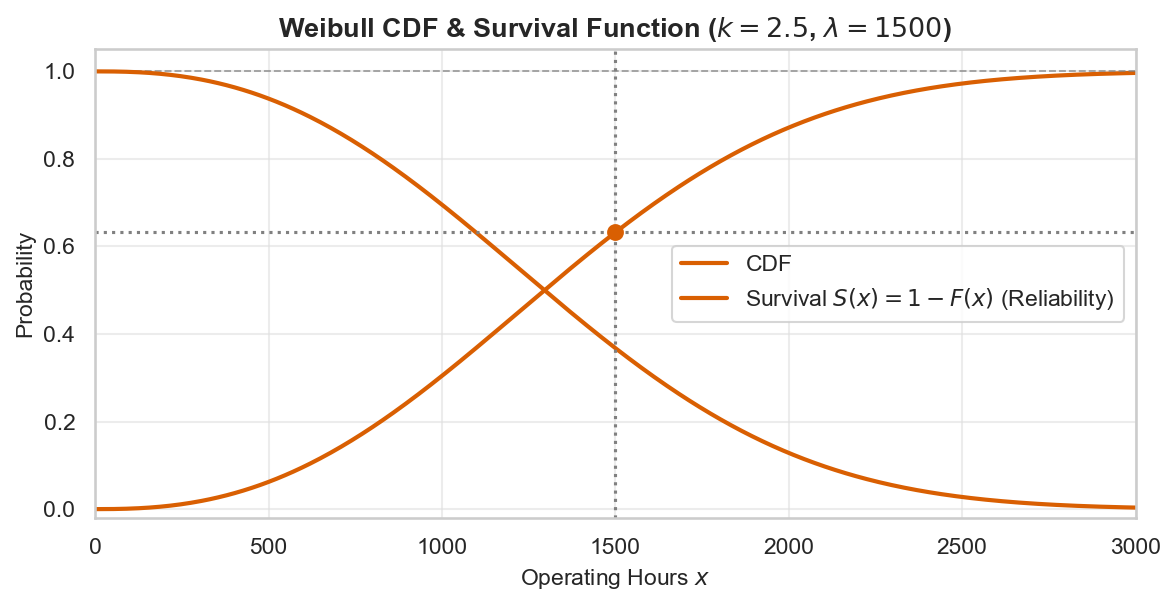

CDF at x = lambda (Cumulative Failure): 0.6321 (Theoretical 1 - 1/e = 0.6321)
Survival S(lambda) (Reliability):       0.3679 (Theoretical 1/e = 0.3679)


In [8]:
cdf_values = weibull_dist.cdf(x_axis)
survival_values = weibull_dist.sf(x_axis)

fig, ax = plt.subplots(figsize=(8, 4.2))
plot_cdf(
    x_axis,
    cdf_values,
    title=rf"Weibull CDF & Survival Function ($k={k_shape}$, $\lambda={lambda_scale:.0f}$)",
    xlabel="Operating Hours $x$",
    ylabel="Probability",
    ax=ax,
)
# Overlay Survival Function S(x)
ax.plot(
    x_axis,
    survival_values,
    color=PALETTE["secondary"],
    linewidth=2.0,
    label="Survival $S(x) = 1 - F(x)$ (Reliability)",
)

# Reference lines at characteristic life x = lambda
p_fail_at_lambda = 1.0 - np.exp(-1.0)
ax.axvline(lambda_scale, color="gray", linestyle=":", linewidth=1.5)
ax.axhline(p_fail_at_lambda, color="gray", linestyle=":", linewidth=1.5)
ax.scatter([lambda_scale], [p_fail_at_lambda], color=PALETTE["secondary"], s=50, zorder=5)

ax.legend(frameon=True, facecolor="white", loc="center right")
ax.set_xlim(0, 3000)
ax.set_ylim(-0.02, 1.05)
plt.tight_layout()
plt.show()

# Display explicit numerical values
f_lambda = float(weibull_dist.cdf(lambda_scale))
s_lambda = float(weibull_dist.sf(lambda_scale))
print(f"CDF at x = lambda (Cumulative Failure): {f_lambda:.4f} (Theoretical 1 - 1/e = {p_fail_at_lambda:.4f})")
print(f"Survival S(lambda) (Reliability):       {s_lambda:.4f} (Theoretical 1/e = {np.exp(-1):.4f})")

## 3. Key Properties & Central Tendencies

All raw moments of $X \sim \text{Weibull}(k, \lambda)$ are determined by the **Gamma function** $\Gamma(z) = \int_0^\infty t^{z-1} e^{-t} dt$:

$$\mathbb{E}[X^r] = \lambda^r \Gamma\left(1 + \frac{r}{k}\right)$$

### 1. Central Tendencies
- **Mode (Peak Density, for $k > 1$):**
  $$\text{Mode} = \lambda \left(\frac{k - 1}{k}\right)^{1/k}$$
  *(For $k \le 1$, the density decreases monotonically and the mode is $0$).*
- **Median (50th Percentile):**
  $$\text{Median} = \lambda (\ln 2)^{1/k} \approx \lambda (0.6931)^{1/k}$$
- **Mean (Expected Value / MTBF):**
  $$\mu = \mathbb{E}[X] = \lambda \Gamma\left(1 + \frac{1}{k}\right)$$

### 2. Variance & Standard Deviation
$$\sigma^2 = \text{Var}(X) = \lambda^2 \left[ \Gamma\left(1 + \frac{2}{k}\right) - \Gamma^2\left(1 + \frac{1}{k}\right) \right]$$

### 3. Skewness ($\gamma_1$)
$$\gamma_1 = \frac{\Gamma\left(1 + \frac{3}{k}\right) - 3\Gamma\left(1 + \frac{1}{k}\right)\Gamma\left(1 + \frac{2}{k}\right) + 2\Gamma^3\left(1 + \frac{1}{k}\right)}{\left[\Gamma\left(1 + \frac{2}{k}\right) - \Gamma^2\left(1 + \frac{1}{k}\right)\right]^{3/2}}$$
- When $k < 3.6$: Positive skew (right-tailed).
- When $k \approx 3.6$: $\gamma_1 \approx 0$ (nearly symmetric, closely mimicking a Normal distribution).
- When $k > 3.6$: Negative skew (left-tailed, wear-out cliff).

In [9]:
from scipy.special import gamma

# Analytical calculations using the Gamma function
g1 = gamma(1.0 + 1.0 / k_shape)
g2 = gamma(1.0 + 2.0 / k_shape)
g3 = gamma(1.0 + 3.0 / k_shape)

mean_analytical = lambda_scale * g1
var_analytical = (lambda_scale**2) * (g2 - g1**2)
std_analytical = np.sqrt(var_analytical)
skew_analytical = (g3 - 3.0 * g1 * g2 + 2.0 * (g1**3)) / ((g2 - g1**2) ** 1.5)

median_analytical = lambda_scale * (np.log(2.0) ** (1.0 / k_shape))
mode_analytical = lambda_scale * (((k_shape - 1.0) / k_shape) ** (1.0 / k_shape))

# SciPy moments: "mvsk" = mean, variance, skew, kurtosis
mean_sp, var_sp, skew_sp, kurt_sp = stats.weibull_min.stats(
    c=k_shape, scale=lambda_scale, moments="mvsk"
)

print("--- WEIBULL THEORETICAL MOMENTS (k = 2.5, lambda = 1500) ---")
print(f"{'Metric':<22} | {'Analytical':>12} | {'SciPy':>12}")
print("-" * 52)
print(f"{'Mean (MTBF)':<22} | {mean_analytical:12.2f} | {float(mean_sp):12.2f}")
print(f"{'Variance':<22} | {var_analytical:12.2f} | {float(var_sp):12.2f}")
print(f"{'Std Deviation':<22} | {std_analytical:12.2f} | {np.sqrt(float(var_sp)):12.2f}")
print(f"{'Skewness (gamma_1)':<22} | {skew_analytical:12.4f} | {float(skew_sp):12.4f}")
print(f"{'Excess Kurtosis':<22} | {'-':>12} | {float(kurt_sp):12.4f}\n")
print(f"Mode:   {mode_analytical:.2f} hr")
print(f"Median: {median_analytical:.2f} hr")
print(f"Mean:   {mean_analytical:.2f} hr  --> Confirms Mode < Median < Mean for right-skewed Weibull!")

--- WEIBULL THEORETICAL MOMENTS (k = 2.5, lambda = 1500) ---
Metric                 |   Analytical |        SciPy
----------------------------------------------------
Mean (MTBF)            |      1330.90 |      1330.90
Variance               |    324330.05 |    324330.05
Std Deviation          |       569.50 |       569.50
Skewness (gamma_1)     |       0.3586 |       0.3586
Excess Kurtosis        |            - |      -0.1432

Mode:   1222.79 hr
Median: 1295.45 hr
Mean:   1330.90 hr  --> Confirms Mode < Median < Mean for right-skewed Weibull!


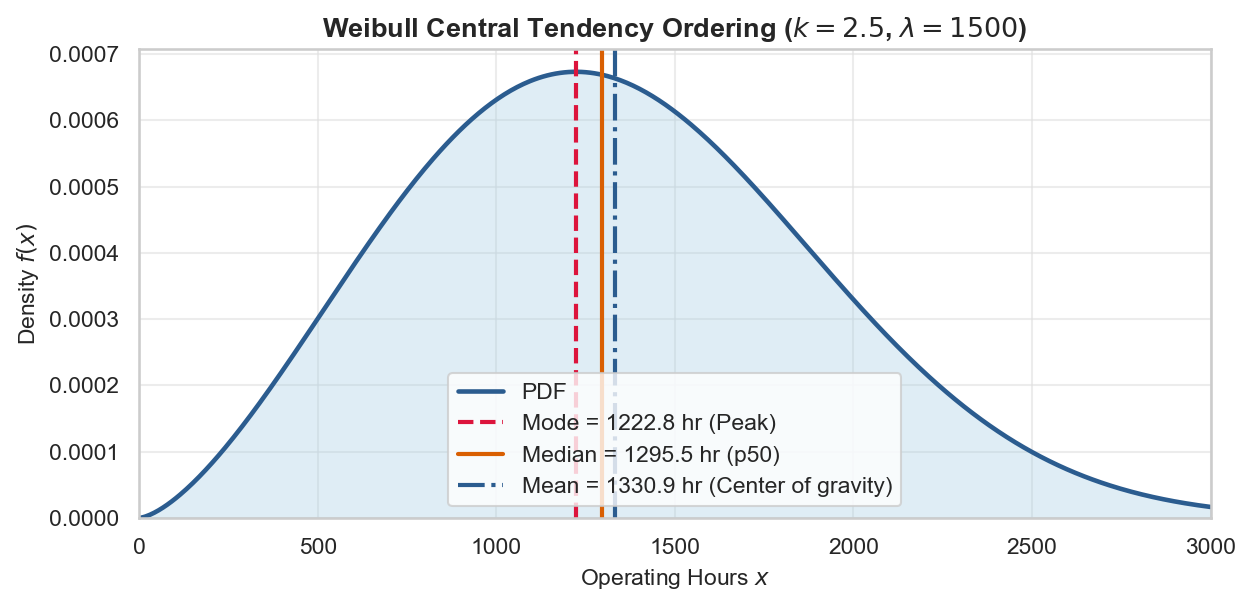

In [10]:
fig, ax = plt.subplots(figsize=(8.5, 4.2))
plot_pdf(
    x_axis,
    pdf_values,
    title=rf"Weibull Central Tendency Ordering ($k={k_shape}$, $\lambda={lambda_scale:.0f}$)",
    xlabel="Operating Hours $x$",
    ylabel="Density $f(x)$",
    fill=True,
    ax=ax,
)

# Overlay Mode, Median, and Mean
ax.axvline(
    mode_analytical,
    color="crimson",
    linestyle="--",
    linewidth=2.0,
    label=rf"Mode = {mode_analytical:.1f} hr (Peak)",
)
ax.axvline(
    median_analytical,
    color=PALETTE["secondary"],
    linestyle="-",
    linewidth=2.0,
    label=rf"Median = {median_analytical:.1f} hr (p50)",
)
ax.axvline(
    mean_analytical,
    color=PALETTE["primary"],
    linestyle="-.",
    linewidth=2.0,
    label=rf"Mean = {mean_analytical:.1f} hr (Center of gravity)",
)

ax.set_xlim(0, 3000)
ax.legend(frameon=True, facecolor="white")
plt.tight_layout()
plt.show()

## 4. Parameter Variation

The two Weibull parameters play fundamentally distinct roles:

### 1. Shape Parameter $k$ (Aging Physics & Geometry)
- **$k < 1$ (Infant Mortality):** Decreasing failure rate; J-shaped density with an asymptote at $x = 0$.
- **$k = 1.0$ (Exponential):** Constant failure rate; memoryless external shocks.
- **$k = 2.0$ (Rayleigh):** Linearly increasing failure rate; electro-mechanical wear.
- **$k \approx 3.6$ (Symmetric Weibull):** Skewness $\gamma_1 \approx 0$; density mimics a Gaussian/Normal bell curve.
- **$k > 3.6$ (Rapid Wear-Out):** Negative skewness; parts reliably survive until a sharp fatigue cliff.

### 2. Scale Parameter $\lambda$ (Characteristic Life)
- Stretches or compresses the distribution along the horizontal time axis.
- Dimensionless shape properties (skewness $\gamma_1$, kurtosis $\gamma_2$) are **completely invariant** to $\lambda$.


--- IMPACT OF SHAPE PARAMETER k (Fixed lambda = 1500 hr) ---
k      |  Mean (hr) |  Mode (hr) |   Skewness | Regime
-----------------------------------------------------------------
0.8    |     1699.5 |        0.0 |      2.815 | Infant Mortality
1.0    |     1500.0 |        0.0 |      2.000 | Memoryless
2.0    |     1329.3 |     1060.7 |      0.631 | Wear-out
3.6    |     1351.7 |     1370.4 |      0.001 | Symmetric
5.0    |     1377.3 |     1434.5 |     -0.254 | Wear-out


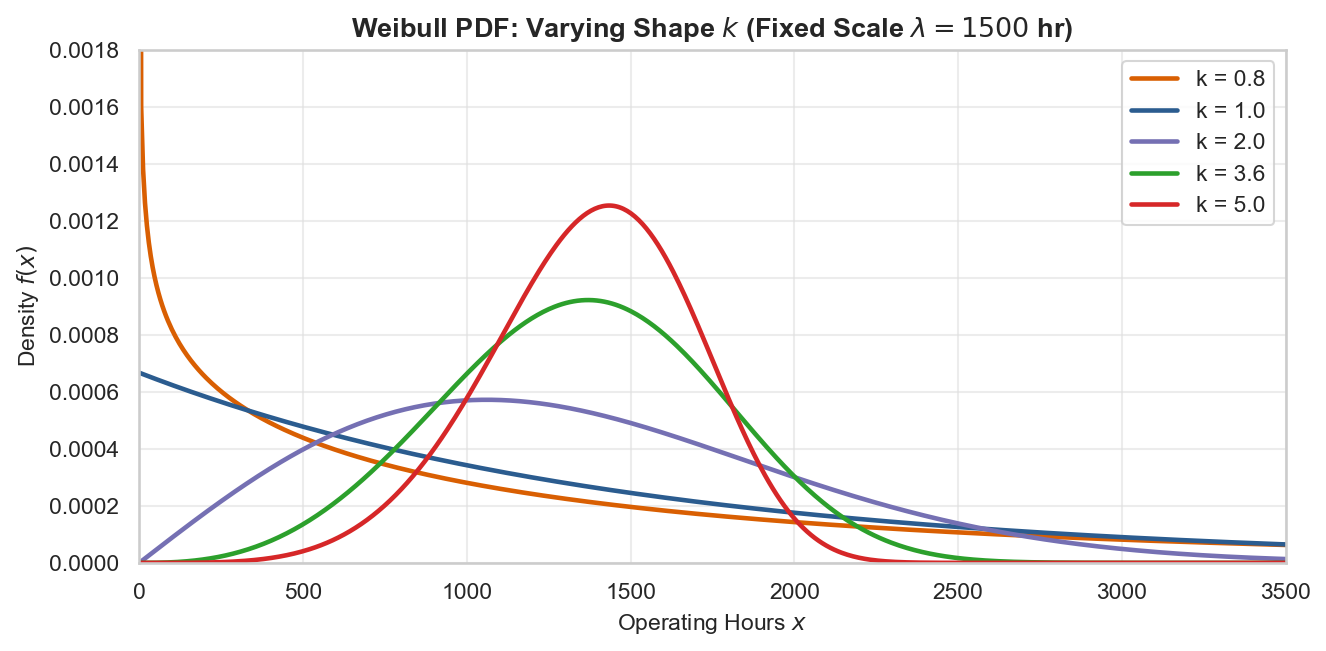

In [11]:
x_grid = np.linspace(1e-2, 3500, 600)
fixed_lambda = 1500.0
k_values = [0.8, 1.0, 2.0, 3.6, 5.0]
curve_colors = [PALETTE["secondary"], PALETTE["primary"], PALETTE["accent"], "#2ca02c", "#d62728"]

fig, ax = plt.subplots(figsize=(9, 4.5))

print("--- IMPACT OF SHAPE PARAMETER k (Fixed lambda = 1500 hr) ---")
print(f"{'k':<6} | {'Mean (hr)':>10} | {'Mode (hr)':>10} | {'Skewness':>10} | Regime")
print("-" * 65)

for k, color in zip(k_values, curve_colors):
    dist = stats.weibull_min(c=k, scale=fixed_lambda)
    pdf = dist.pdf(x_grid)
    ax.plot(x_grid, pdf, label=f"k = {k}", color=color, linewidth=2.2)

    # Compute regime summary metrics
    m_val = float(dist.mean())
    mode_val = fixed_lambda * (((k - 1) / k) ** (1 / k)) if k > 1 else 0.0
    _, _, skew_val, _ = dist.stats(moments="mvsk")
    regime = "Infant Mortality" if k < 1 else ("Memoryless" if k == 1 else ("Symmetric" if k == 3.6 else "Wear-out"))
    print(f"{k:<6.1f} | {m_val:10.1f} | {mode_val:10.1f} | {float(skew_val):10.3f} | {regime}")

ax.set_title(rf"Weibull PDF: Varying Shape $k$ (Fixed Scale $\lambda = {fixed_lambda:.0f}$ hr)", fontsize=13, fontweight="bold")
ax.set_xlabel("Operating Hours $x$", fontsize=11)
ax.set_ylabel("Density $f(x)$", fontsize=11)
ax.set_ylim(0, 0.0018)
ax.set_xlim(0, 3500)
ax.legend(frameon=True, facecolor="white")
plt.tight_layout()
plt.show()


--- IMPACT OF SCALE PARAMETER lambda (Fixed k = 2.5) ---
lambda (hr)  |  Mean (hr) |  Median (hr) |   Skewness
----------------------------------------------------
600.0        |      532.4 |        518.2 |     0.3586
1200.0       |     1064.7 |       1036.4 |     0.3586
1800.0       |     1597.1 |       1554.5 |     0.3586
2400.0       |     2129.4 |       2072.7 |     0.3586


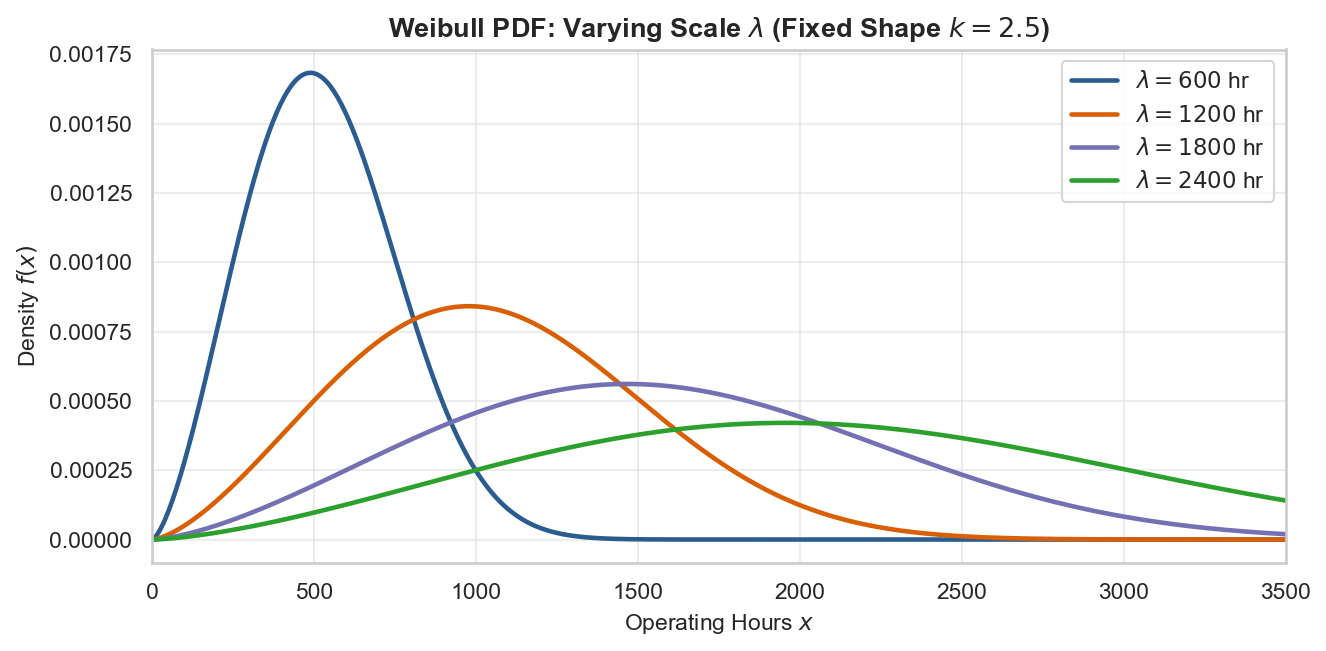

In [12]:
fixed_k = 2.5
lambda_values = [600.0, 1200.0, 1800.0, 2400.0]
scale_colors = [PALETTE["primary"], PALETTE["secondary"], PALETTE["accent"], "#2ca02c"]

fig, ax = plt.subplots(figsize=(9, 4.5))

print("\n--- IMPACT OF SCALE PARAMETER lambda (Fixed k = 2.5) ---")
print(f"{'lambda (hr)':<12} | {'Mean (hr)':>10} | {'Median (hr)':>12} | {'Skewness':>10}")
print("-" * 52)

for lmb, color in zip(lambda_values, scale_colors):
    dist = stats.weibull_min(c=fixed_k, scale=lmb)
    pdf = dist.pdf(x_grid)
    ax.plot(x_grid, pdf, label=rf"$\lambda = {lmb:.0f}$ hr", color=color, linewidth=2.2)

    # Numerical metrics
    m_val = float(dist.mean())
    med_val = float(dist.median())
    _, _, skew_val, _ = dist.stats(moments="mvsk")
    print(f"{lmb:<12.1f} | {m_val:10.1f} | {med_val:12.1f} | {float(skew_val):10.4f}")

ax.set_title(rf"Weibull PDF: Varying Scale $\lambda$ (Fixed Shape $k = {fixed_k}$)", fontsize=13, fontweight="bold")
ax.set_xlabel("Operating Hours $x$", fontsize=11)
ax.set_ylabel("Density $f(x)$", fontsize=11)
ax.set_xlim(0, 3500)
ax.legend(frameon=True, facecolor="white")
plt.tight_layout()
plt.show()

## 5. Simulation & Empirical Verification

### 1. Inverse Transform Sampling
Because the Weibull CDF has a simple closed form, we can invert it analytically:
$$U = F(X) = 1 - \exp\left(-\left(\frac{X}{\lambda}\right)^k\right), \quad U \sim \text{Uniform}(0, 1)$$

Solving for $X$:
$$1 - U = \exp\left(-\left(\frac{X}{\lambda}\right)^k\right) \implies \ln(1 - U) = -\left(\frac{X}{\lambda}\right)^k$$
$$X = \lambda \left(-\ln(1 - U)\right)^{1/k}$$

Since $(1 - U) \sim \text{Uniform}(0, 1)$, we can generate exact Weibull variates directly:
$$X = \lambda \left(-\ln U\right)^{1/k}, \quad U \sim \text{Uniform}(0, 1)$$

### 2. Law of Large Numbers (LLN)
By the Strong Law of Large Numbers, the sample mean $\bar{X}_n = \frac{1}{n} \sum_{i=1}^n X_i$ converges almost surely to the true mean $\mu = \lambda \Gamma(1 + 1/k)$ as $n \to \infty$.

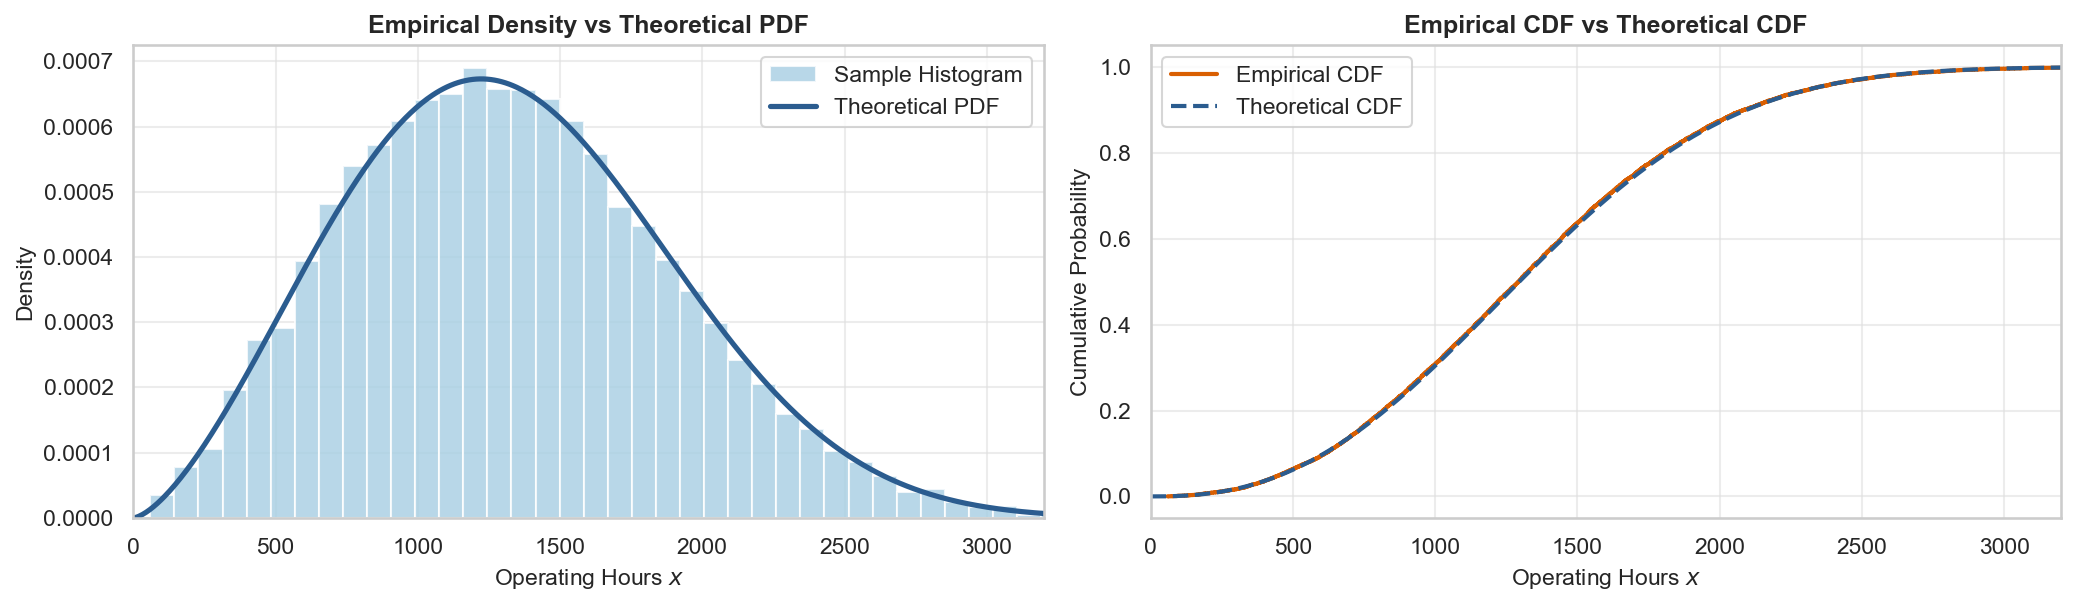

Sample Mean:     1326.16 hr | Theoretical Mean:     1330.90 hr (Diff: 4.73)
Sample Variance: 324787.8    | Theoretical Variance: 324330.1


In [13]:
# Parameters
sample_size = 10000
sim_k = 2.5
sim_lambda = 1500.0

rng = np.random.default_rng(seed=42)

# Generate variates using SciPy (equivalent to inverse transform)
samples_weibull = stats.weibull_min.rvs(c=sim_k, scale=sim_lambda, size=sample_size, random_state=rng)

# Theoretical targets
weibull_ref = stats.weibull_min(c=sim_k, scale=sim_lambda)
mu_theoretical = float(weibull_ref.mean())
var_theoretical = float(weibull_ref.var())

# Visualizing Sample vs Theory
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.2))

# Subplot 1: Histogram vs Theoretical PDF
x_eval = np.linspace(0.01, 3200, 500)
ax1.hist(samples_weibull, bins=45, density=True, color=PALETTE["fill"], edgecolor="white", alpha=0.8, label="Sample Histogram")
ax1.plot(x_eval, weibull_ref.pdf(x_eval), color=PALETTE["primary"], linewidth=2.5, label="Theoretical PDF")
ax1.set_title("Empirical Density vs Theoretical PDF", fontsize=12, fontweight="bold")
ax1.set_xlabel("Operating Hours $x$", fontsize=11)
ax1.set_ylabel("Density", fontsize=11)
ax1.set_xlim(0, 3200)
ax1.legend(frameon=True, facecolor="white")

# Subplot 2: Empirical CDF vs Theoretical CDF
sorted_samples = np.sort(samples_weibull)
empirical_cdf = np.arange(1, sample_size + 1) / sample_size
ax2.step(sorted_samples, empirical_cdf, color=PALETTE["secondary"], linewidth=2.0, label="Empirical CDF")
ax2.plot(x_eval, weibull_ref.cdf(x_eval), color=PALETTE["primary"], linestyle="--", linewidth=2.0, label="Theoretical CDF")
ax2.set_title("Empirical CDF vs Theoretical CDF", fontsize=12, fontweight="bold")
ax2.set_xlabel("Operating Hours $x$", fontsize=11)
ax2.set_ylabel("Cumulative Probability", fontsize=11)
ax2.set_xlim(0, 3200)
ax2.legend(frameon=True, facecolor="white")

plt.tight_layout()
plt.show()

# Print explicit numerical comparisons
sample_mean = float(np.mean(samples_weibull))
sample_var = float(np.var(samples_weibull, ddof=1))
print(f"Sample Mean:     {sample_mean:.2f} hr | Theoretical Mean:     {mu_theoretical:.2f} hr (Diff: {abs(sample_mean - mu_theoretical):.2f})")
print(f"Sample Variance: {sample_var:.1f}    | Theoretical Variance: {var_theoretical:.1f}")

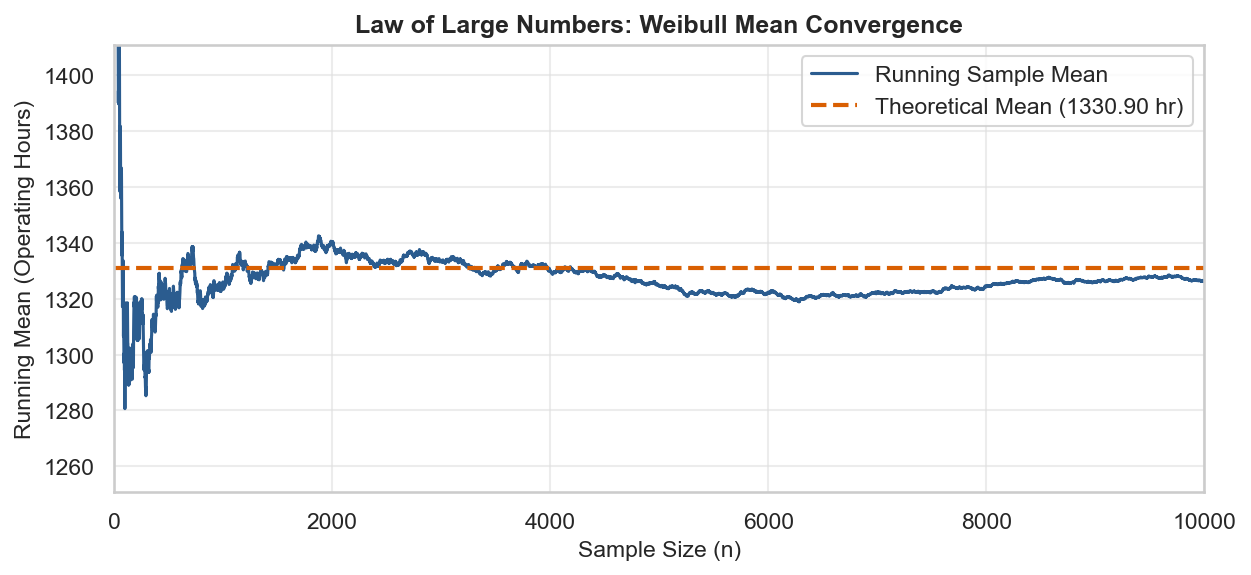

Final Running Mean at n = 10000: 1326.16 hours
Relative Estimation Error:             0.356%


In [14]:
running_mean = np.cumsum(samples_weibull) / np.arange(1, sample_size + 1)

fig, ax = plt.subplots(figsize=(8.5, 4.0))
ax.plot(running_mean, color=PALETTE["primary"], linewidth=1.5, label="Running Sample Mean")
ax.axhline(mu_theoretical, color=PALETTE["secondary"], linestyle="--", linewidth=2.0, label=f"Theoretical Mean ({mu_theoretical:.2f} hr)")

ax.set_title("Law of Large Numbers: Weibull Mean Convergence", fontsize=12, fontweight="bold")
ax.set_xlabel("Sample Size (n)", fontsize=11)
ax.set_ylabel("Running Mean (Operating Hours)", fontsize=11)
ax.set_ylim(mu_theoretical - 80, mu_theoretical + 80)
ax.set_xlim(0, sample_size)
ax.legend(frameon=True, facecolor="white")

plt.tight_layout()
plt.show()

final_error_pct = abs(running_mean[-1] - mu_theoretical) / mu_theoretical * 100.0
print(f"Final Running Mean at n = {sample_size}: {running_mean[-1]:.2f} hours")
print(f"Relative Estimation Error:             {final_error_pct:.3f}%")

## 6. Applied Use Case: Offshore Wind Turbine Bearing Fatigue Life

An offshore wind farm operates a fleet of **500 turbines**. Each turbine's main shaft roller bearing is subject to cyclic mechanical stress and fatigue wear-out.

Reliability testing models bearing operational life using a Weibull distribution:
- **Shape parameter $k = 3.2$:** Accelerated mechanical wear-out ($k > 1$).
- **Scale parameter $\lambda = 45,000$ operating hours:** Characteristic life ($\approx 5.1$ years of continuous generation).

### Key Engineering Questions:
1. **$B_{10}$ Life (Rating Life):** At what operational hour will $10\%$ of the bearing fleet fail ($F(t) = 0.10$)?
   $$B_{10} = \lambda \left(-\ln(1 - 0.10)\right)^{1/k} = \lambda \left(\ln \frac{1}{0.90}\right)^{1/k}$$
2. **Warranty Exposure:** What percentage of bearings survive the manufacturer's **3-year warranty** ($26,280$ hours)?
3. **Preventative Maintenance Window:** Catastrophic offshore failure costs **$\$250,000$** (emergency jack-up vessel + gearbox replacement), whereas scheduled preventative overhaul costs **$\$40,000$**. When should overhauls be scheduled?

In [15]:
k_bearing = 3.2
lambda_bearing = 45000.0  # hours
n_turbines = 500
warranty_hours = 3 * 365.25 * 24  # 3 years = 26,298 hours

bearing_dist = stats.weibull_min(c=k_bearing, scale=lambda_bearing)

# Analytical B-lives (Quantiles / Percentiles)
b1_life = float(bearing_dist.ppf(0.01))
b10_life = float(bearing_dist.ppf(0.10))
median_life = float(bearing_dist.ppf(0.50))
mean_life = float(bearing_dist.mean())

# Survival probabilities
survival_warranty = float(bearing_dist.sf(warranty_hours))
expected_warranty_failures = n_turbines * (1.0 - survival_warranty)

# Cost analysis
cost_unplanned = 250000.0  # $ per catastrophic failure
cost_planned = 40000.0     # $ per scheduled overhaul
fleet_warranty_risk = expected_warranty_failures * cost_unplanned

print("--- OFFSHORE WIND TURBINE BEARING RELIABILITY (500 TURBINES) ---")
print(f"B1 Life  (99% Reliability milestone):      {b1_life:10.1f} operating hours")
print(f"B10 Life (90% Reliability / ISO Rating):    {b10_life:10.1f} operating hours")
print(f"Median Life (50% failure milestone):        {median_life:10.1f} operating hours")
print(f"Mean Time to Failure (MTTF):                {mean_life:10.1f} operating hours")
print("-" * 65)
print(f"3-Year Warranty Survival Probability S(t): {survival_warranty * 100:.2f}%")
print(f"Expected Failures under 3-Yr Warranty:     {expected_warranty_failures:.1f} of {n_turbines} turbines")
print(f"Expected Warranty Liability Exposure:      ${fleet_warranty_risk:,.2f}")

--- OFFSHORE WIND TURBINE BEARING RELIABILITY (500 TURBINES) ---
B1 Life  (99% Reliability milestone):         10687.9 operating hours
B10 Life (90% Reliability / ISO Rating):       22274.1 operating hours
Median Life (50% failure milestone):           40130.1 operating hours
Mean Time to Failure (MTTF):                   40304.4 operating hours
-----------------------------------------------------------------
3-Year Warranty Survival Probability S(t): 83.59%
Expected Failures under 3-Yr Warranty:     82.1 of 500 turbines
Expected Warranty Liability Exposure:      $20,513,469.78


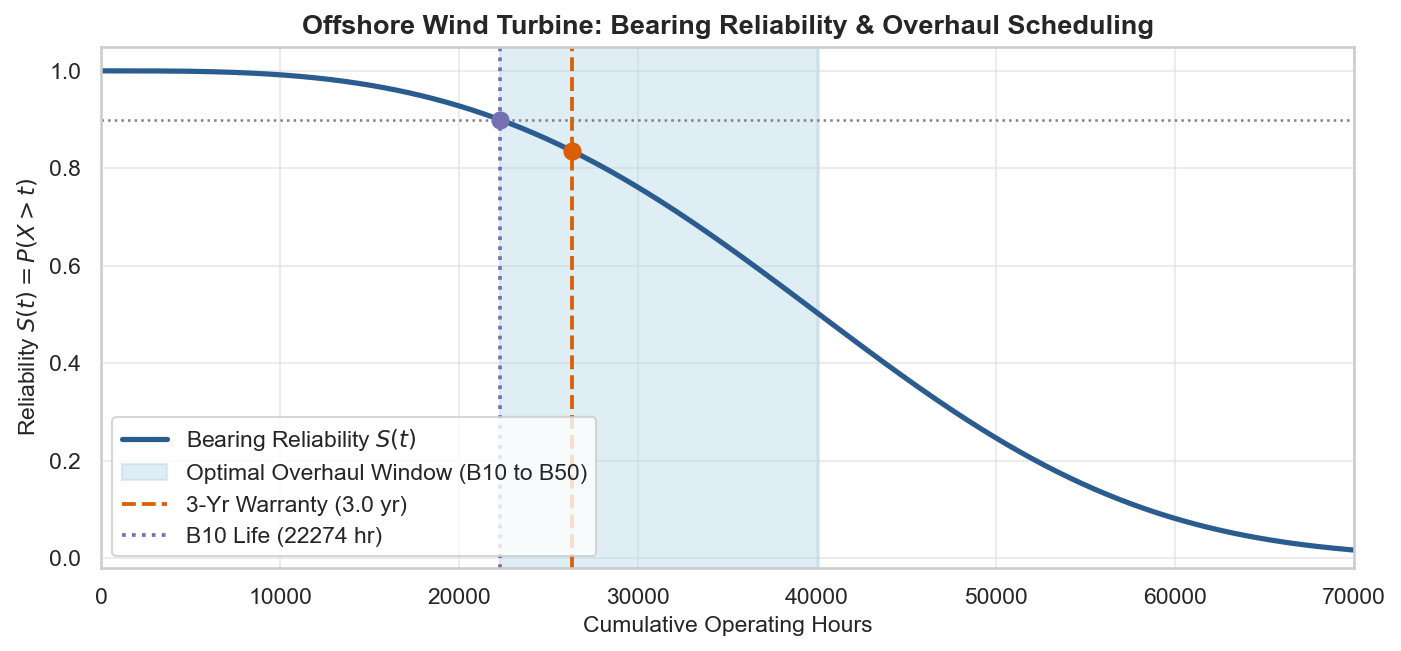

In [16]:
hours_grid = np.linspace(0, 70000, 600)
survival_curve = bearing_dist.sf(hours_grid)

fig, ax = plt.subplots(figsize=(9.5, 4.5))

# Plot Survival Function (Reliability)
ax.plot(hours_grid, survival_curve, color=PALETTE["primary"], linewidth=2.5, label="Bearing Reliability $S(t)$")

# Highlight Preventative Maintenance Window (Between B10 and B50)
ax.axvspan(b10_life, median_life, color=PALETTE["fill"], alpha=0.35, label="Optimal Overhaul Window (B10 to B50)")

# Key Milestone Reference Lines
ax.axvline(warranty_hours, color=PALETTE["secondary"], linestyle="--", linewidth=1.8, label=f"3-Yr Warranty ({warranty_hours/8766:.1f} yr)")
ax.axvline(b10_life, color=PALETTE["accent"], linestyle=":", linewidth=1.8, label=f"B10 Life ({b10_life:.0f} hr)")
ax.axhline(0.90, color="gray", linestyle=":", linewidth=1.2)

# Scatter milestone points
ax.scatter([b10_life], [0.90], color=PALETTE["accent"], s=60, zorder=5)
ax.scatter([warranty_hours], [survival_warranty], color=PALETTE["secondary"], s=60, zorder=5)

ax.set_title("Offshore Wind Turbine: Bearing Reliability & Overhaul Scheduling", fontsize=13, fontweight="bold")
ax.set_xlabel("Cumulative Operating Hours", fontsize=11)
ax.set_ylabel("Reliability $S(t) = P(X > t)$", fontsize=11)
ax.set_xlim(0, 70000)
ax.set_ylim(-0.02, 1.05)
ax.legend(frameon=True, facecolor="white", loc="lower left")

plt.tight_layout()
plt.show()

## 7. Parameter Estimation: Maximum Likelihood Estimation (MLE)

Given an independent sample $x = (x_1, x_2, \dots, x_n)$ from $\text{Weibull}(k, \lambda)$, the likelihood function is:

$$L(k, \lambda) = \prod_{i=1}^n \frac{k}{\lambda} \left(\frac{x_i}{\lambda}\right)^{k-1} \exp\left(-\left(\frac{x_i}{\lambda}\right)^k\right)$$

Taking the natural logarithm yields the **log-likelihood function** $\ell(k, \lambda)$:
$$\ell(k, \lambda) = n \ln k - n k \ln \lambda + (k - 1) \sum_{i=1}^n \ln x_i - \sum_{i=1}^n \left(\frac{x_i}{\lambda}\right)^k$$

### Score Equations
Setting partial derivatives to zero:
1. **With respect to $\lambda$:**
   $$\frac{\partial \ell}{\partial \lambda} = -\frac{n k}{\lambda} + \frac{k}{\lambda^{k+1}} \sum_{i=1}^n x_i^k = 0 \implies \hat{\lambda} = \left(\frac{1}{n} \sum_{i=1}^n x_i^k\right)^{1/k}$$

2. **With respect to $k$:**
   $$\frac{\partial \ell}{\partial k} = \frac{n}{k} - n \ln \hat{\lambda} + \sum_{i=1}^n \ln x_i - \sum_{i=1}^n \left(\frac{x_i}{\hat{\lambda}}\right)^k \ln\left(\frac{x_i}{\hat{\lambda}}\right) = 0$$

Because the equation for $k$ is transcendental (combining $1/k$ and $x^k \ln x$), there is **no closed-form analytical solution**. We must solve for $\hat{k}$ and $\hat{\lambda}$ using numerical optimization.

In [17]:
from scipy.optimize import minimize

# Generate synthetic dataset with known ground truth
n_obs = 1500
true_k = 2.4
true_lambda = 1200.0

rng = np.random.default_rng(seed=42)
data_sample = stats.weibull_min.rvs(c=true_k, scale=true_lambda, size=n_obs, random_state=rng)

# Negative Log-Likelihood objective function
def neg_log_likelihood(params, data):
    k, lmb = params
    if k <= 0 or lmb <= 0:
        return 1e12  # Penalty for non-positive parameter values
    n = len(data)
    log_l = n * np.log(k) - n * k * np.log(lmb) + (k - 1.0) * np.sum(np.log(data)) - np.sum((data / lmb) ** k)
    return -log_l

# 1. Custom numerical optimization via minimize
init_guess = [1.5, np.mean(data_sample)]
opt_result = minimize(neg_log_likelihood, init_guess, args=(data_sample,), method="L-BFGS-B", bounds=[(1e-2, None), (1e-2, None)])
mle_k, mle_lambda = opt_result.x

# 2. SciPy built-in fit (fix location parameter to 0)
sp_shape, sp_loc, sp_scale = stats.weibull_min.fit(data_sample, floc=0)

# Display parameter comparison table
print("--- WEIBULL MAXIMUM LIKELIHOOD ESTIMATION (N = 1,500) ---")
print(f"{'Parameter':<18} | {'Ground Truth':>12} | {'Custom MLE':>12} | {'SciPy Fit':>12}")
print("-" * 62)
print(f"{'Shape (k)':<18} | {true_k:12.4f} | {mle_k:12.4f} | {sp_shape:12.4f}")
print(f"{'Scale (lambda)':<18} | {true_lambda:12.2f} | {mle_lambda:12.2f} | {sp_scale:12.2f}")

err_k = abs(mle_k - true_k) / true_k * 100
err_lmb = abs(mle_lambda - true_lambda) / true_lambda * 100
print(f"\nShape estimation error: {err_k:.2f}% | Scale estimation error: {err_lmb:.2f}%")

--- WEIBULL MAXIMUM LIKELIHOOD ESTIMATION (N = 1,500) ---
Parameter          | Ground Truth |   Custom MLE |    SciPy Fit
--------------------------------------------------------------
Shape (k)          |       2.4000 |       2.3704 |       2.3704
Scale (lambda)     |      1200.00 |      1202.69 |      1202.70

Shape estimation error: 1.23% | Scale estimation error: 0.22%


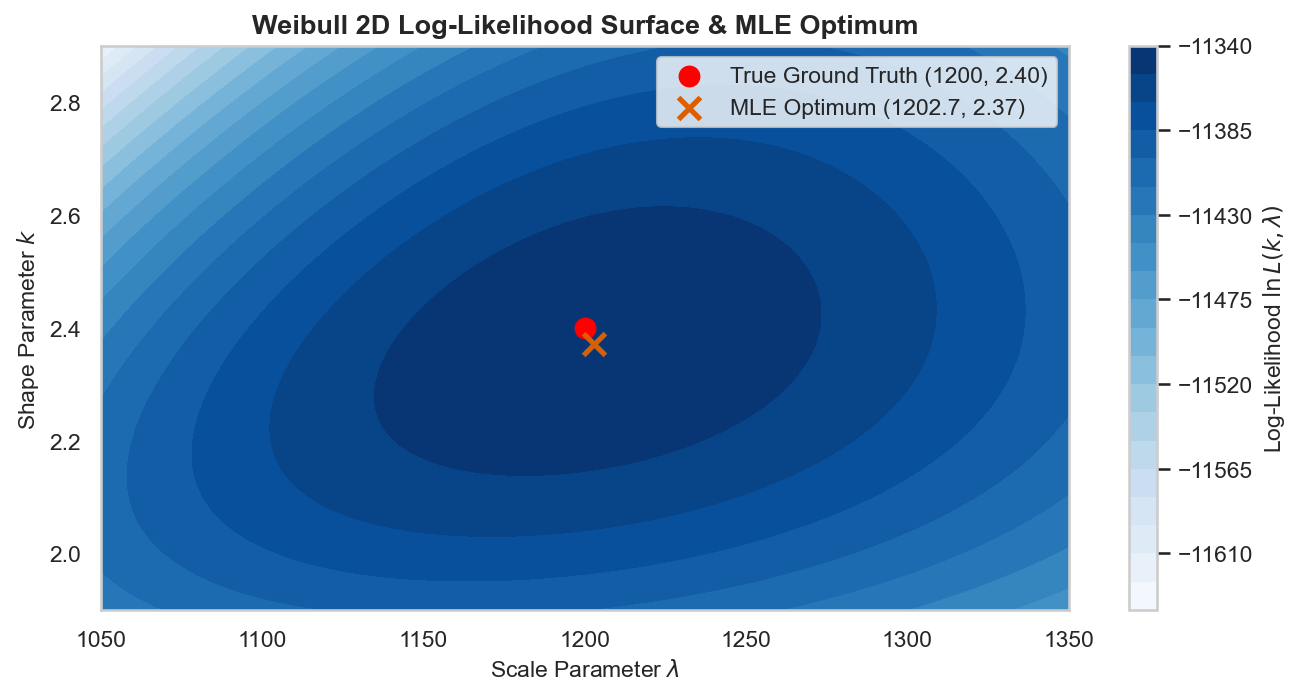

In [18]:
# Create grid around optimum
k_range = np.linspace(true_k - 0.5, true_k + 0.5, 80)
lambda_range = np.linspace(true_lambda - 150, true_lambda + 150, 80)
K_grid, L_grid = np.meshgrid(k_range, lambda_range)

# Evaluate log-likelihood on 2D grid
log_lik_grid = np.zeros_like(K_grid)
for i in range(K_grid.shape[0]):
    for j in range(K_grid.shape[1]):
        log_lik_grid[i, j] = -neg_log_likelihood([K_grid[i, j], L_grid[i, j]], data_sample)

fig, ax = plt.subplots(figsize=(9, 4.8))
contour = ax.contourf(L_grid, K_grid, log_lik_grid, levels=25, cmap="Blues")
cbar = plt.colorbar(contour, ax=ax)
cbar.set_label("Log-Likelihood $\\ln L(k, \\lambda)$", fontsize=11)

# Overlay True vs MLE markers
ax.scatter([true_lambda], [true_k], color="red", s=90, marker="o", label=f"True Ground Truth ({true_lambda:.0f}, {true_k:.2f})", zorder=5)
ax.scatter([mle_lambda], [mle_k], color=PALETTE["secondary"], s=110, marker="x", linewidth=2.5, label=f"MLE Optimum ({mle_lambda:.1f}, {mle_k:.2f})", zorder=6)

ax.set_title("Weibull 2D Log-Likelihood Surface & MLE Optimum", fontsize=13, fontweight="bold")
ax.set_xlabel("Scale Parameter $\\lambda$", fontsize=11)
ax.set_ylabel("Shape Parameter $k$", fontsize=11)
ax.legend(frameon=True, facecolor="white", loc="upper right")

plt.tight_layout()
plt.show()

## 8. Related Distributions & Summary

The Weibull distribution is a **hub** in lifetime modeling: it generalizes the Exponential, contains the Rayleigh as a special case, and is tied to the Gumbel (extreme-value) family through a simple log transform.

1. **Exponential Distribution ($k = 1$)**:
   - $\text{Weibull}(k = 1, \lambda) \equiv \text{Exponential}(\text{mean} = \lambda)$, i.e. rate $= 1/\lambda$.
   - The hazard becomes constant, $h(x) = 1/\lambda$, which is exactly the memoryless property from Section 1.
   - The Weibull adds a single parameter ($k$) that lets the failure rate *change with age*.

2. **Rayleigh Distribution ($k = 2$)**:
   - $\text{Weibull}(k = 2, \lambda) \equiv \text{Rayleigh}(\sigma = \lambda / \sqrt{2})$.
   - Models the length of a 2D Gaussian vector $\sqrt{Z_1^2 + Z_2^2}$ (wind speed, signal amplitude) and has a hazard that grows linearly in time.

3. **Power Transformation of the Exponential**:
   - If $Y \sim \text{Exponential}(1)$, then
     $$X = \lambda\, Y^{1/k} \sim \text{Weibull}(k, \lambda) \quad \Longleftrightarrow \quad \left(\frac{X}{\lambda}\right)^k \sim \text{Exponential}(1)$$
   - This is the same identity used for inverse-transform sampling in Section 5, and it means every Weibull is just a *time-warped* Exponential.

4. **Gumbel (Smallest Extreme Value) Distribution**:
   - If $X \sim \text{Weibull}(k, \lambda)$, then $\ln X \sim \text{Gumbel}_{\min}\big(\text{loc} = \ln \lambda, \ \text{scale} = 1/k\big)$.
   - Taking logs turns the Weibull *scale* into a *location* shift and the *shape* into a *scale*, which is why log-lifetime regression (Accelerated Failure Time models) works so naturally.
   - Linearizing the CDF gives the **Weibull probability plot**: $\ln\!\big(-\ln S(x)\big) = k \ln x - k \ln \lambda$, a straight line with slope $k$.

5. **Extreme Value Theory & the Weakest-Link Principle**:
   - The Weibull is the limiting distribution of the **minimum** of many i.i.d. positive random variables (Type III extreme value law for minima).
   - It is also **min-stable**: the minimum of $m$ i.i.d. $\text{Weibull}(k, \lambda)$ lifetimes is again Weibull with the same shape and a smaller scale:
     $$\min(X_1, \dots, X_m) \sim \text{Weibull}\left(k, \ \lambda \, m^{-1/k}\right)$$
   - This models **series systems** (a chain fails when its weakest link fails) and the **size effect** in material strength: larger parts are weaker.

6. **Normal Distribution (near $k \approx 3.6$)**:
   - Skewness vanishes around $k \approx 3.6$, so the Weibull is approximately bell-shaped. This is a coincidence of shape, not a limit theorem.

7. **Competing Lifetime Models (Gamma, Log-Normal)**:
   - **Gamma**: also generalizes the Exponential, but its hazard levels off to a constant. The Weibull hazard can grow without bound ($k > 1$) or vanish ($k < 1$).
   - **Log-Normal**: hazard rises then falls (non-monotone), common for repair times and fatigue crack growth.
   - Fit several candidates and compare using AIC/BIC or a probability plot.

8. **Generalizations**:
   - **3-parameter Weibull**: adds a location $\gamma$ (failure-free period), $X - \gamma \sim \text{Weibull}(k, \lambda)$. In SciPy: `weibull_min(c, loc, scale)`.
   - **Weibull mixtures**: combine sub-populations (e.g. early defects and wear-out) to reproduce the **bathtub curve**.
   - **Inverse Weibull (Fréchet)**: $1/X$ follows a Fréchet distribution (Type II extreme value law for maxima)

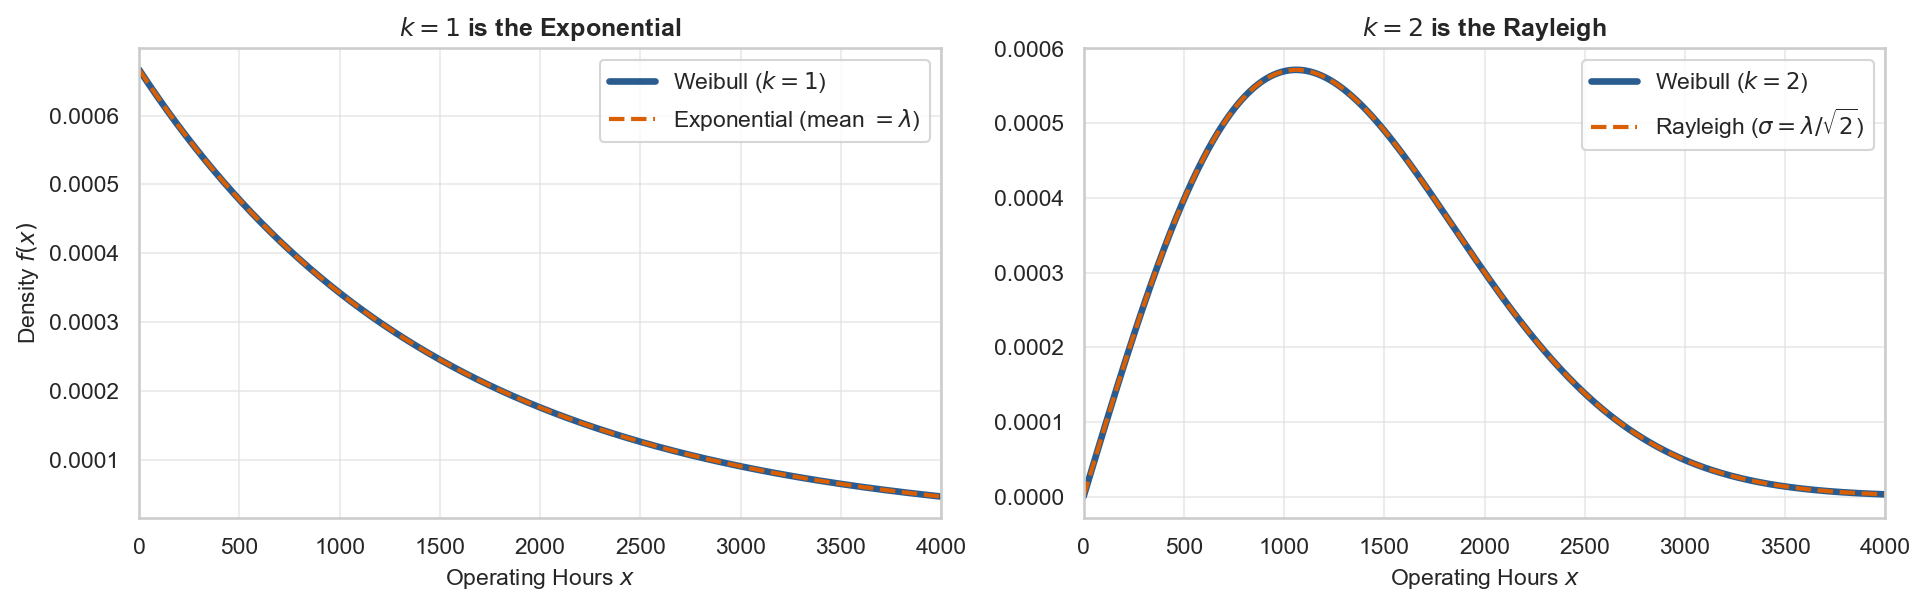

Max |PDF difference|, Weibull(k=1) vs Exponential: 0.00e+00
Max |PDF difference|, Weibull(k=2) vs Rayleigh:    2.17e-19


In [20]:
x_cmp = np.linspace(0.01, 4000, 600)
lam_cmp = 1500.0

# k = 1  ->  Exponential with mean lambda
weib_k1 = stats.weibull_min(c=1.0, scale=lam_cmp)
expon_ref = stats.expon(scale=lam_cmp)

# k = 2  ->  Rayleigh with sigma = lambda / sqrt(2)
weib_k2 = stats.weibull_min(c=2.0, scale=lam_cmp)
rayleigh_ref = stats.rayleigh(scale=lam_cmp / np.sqrt(2.0))

max_diff_exp = np.max(np.abs(weib_k1.pdf(x_cmp) - expon_ref.pdf(x_cmp)))
max_diff_ray = np.max(np.abs(weib_k2.pdf(x_cmp) - rayleigh_ref.pdf(x_cmp)))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
cases = [
    (axes[0], weib_k1, expon_ref, "Weibull ($k=1$)", "Exponential (mean $=\\lambda$)", "$k = 1$ is the Exponential"),
    (axes[1], weib_k2, rayleigh_ref, "Weibull ($k=2$)", "Rayleigh ($\\sigma=\\lambda/\\sqrt{2}$)", "$k = 2$ is the Rayleigh"),
]
for ax, w_dist, ref_dist, w_label, ref_label, title in cases:
    ax.plot(x_cmp, w_dist.pdf(x_cmp), color=PALETTE["primary"], linewidth=3.2, label=w_label)
    ax.plot(x_cmp, ref_dist.pdf(x_cmp), color=PALETTE["secondary"], linestyle="--", linewidth=2.0, label=ref_label)
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_xlabel("Operating Hours $x$", fontsize=11)
    ax.set_xlim(0, 4000)
    ax.legend(frameon=True, facecolor="white")
axes[0].set_ylabel("Density $f(x)$", fontsize=11)

plt.tight_layout()
plt.show()

print(f"Max |PDF difference|, Weibull(k=1) vs Exponential: {max_diff_exp:.2e}")
print(f"Max |PDF difference|, Weibull(k=2) vs Rayleigh:    {max_diff_ray:.2e}")

### Summary Card: Weibull Distribution

| Property | Formulation |
| :--- | :--- |
| **Notation** | $X \sim \text{Weibull}(k, \lambda)$ |
| **Parameters** | $k > 0$ (shape), $\lambda > 0$ (scale / characteristic life) |
| **Support** | $x \in [0, \infty)$ |
| **PDF** | $f(x) = \frac{k}{\lambda}\left(\frac{x}{\lambda}\right)^{k-1} e^{-(x/\lambda)^k}$ |
| **CDF** | $F(x) = 1 - e^{-(x/\lambda)^k}$ |
| **Survival Function** | $S(x) = e^{-(x/\lambda)^k}$ |
| **Hazard Function** | $h(x) = \frac{k}{\lambda}\left(\frac{x}{\lambda}\right)^{k-1}$ |
| **Quantile Function** | $x_p = \lambda\left(-\ln(1 - p)\right)^{1/k}$ |
| **Mean ($\mu$)** | $\lambda\, \Gamma\left(1 + \frac{1}{k}\right)$ |
| **Median** | $\lambda\, (\ln 2)^{1/k}$ |
| **Mode** | $\lambda \left(\frac{k-1}{k}\right)^{1/k}$ for $k > 1$, otherwise $0$ |
| **Variance ($\sigma^2$)** | $\lambda^2\left[\Gamma\left(1 + \frac{2}{k}\right) - \Gamma^2\left(1 + \frac{1}{k}\right)\right]$ |
| **Skewness ($\gamma_1$)** | $\frac{\Gamma_3 - 3\Gamma_1\Gamma_2 + 2\Gamma_1^3}{(\Gamma_2 - \Gamma_1^2)^{3/2}}$, with $\Gamma_i = \Gamma\left(1 + \frac{i}{k}\right)$ |
| **MLE Estimator** | $\hat{\lambda} = \left(\frac{1}{n}\sum x_i^{\hat{k}}\right)^{1/\hat{k}}$; $\hat{k}$ solved numerically (no closed form) |
| **Special Cases** | $k = 1$ Exponential, $k = 2$ Rayleigh |
| **Key Links** | $\ln X \sim$ Gumbel-min; min-stable under series systems |
| **Key Use Cases** | Reliability engineering, warranty analysis, survival analysis, wind speed modeling, material fatigue